# Урок 8. Полный ML-пайплайн на собственном датасете

**Студент:** Плисак Арсений Сергеевич

Задание из репозитория преподавателя: пройти весь процесс машинного обучения на
самостоятельно найденном датасете — регрессия, классификация, масштабирование,
метрики, деревья и случайный лес, сравнение моделей и выводы.

## Задание 1. Загрузка библиотек

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_score, r2_score,
                             recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)

## Задание 2. Загрузка датасета

**Датасет:** California Housing — данные переписи населения Калифорнии 1990 года.
Опубликован на Kaggle как «California Housing Prices», в работе загружен через
`sklearn.datasets.fetch_california_housing` и сохранён в `dataset.csv`.

Проверка требований задания: 20 640 строк при минимуме 150, восемь признаков при
минимуме пяти, числовая колонка `MedHouseVal` для регрессии. Готовой колонки-класса
нет, поэтому её нужно создать самостоятельно.

In [2]:
df = pd.read_csv("dataset.csv")
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("Размер таблицы:", df.shape)

Размер таблицы: (20640, 9)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


## Задание 3. Первичный анализ данных

In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [6]:
print("Пропуски по колонкам:")
print(df.isnull().sum().to_string())
print("\nВсего пропусков:", int(df.isnull().sum().sum()))

Пропуски по колонкам:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0

Всего пропусков: 0


In [7]:
duplicates = df.duplicated().sum()
print("Дубликатов:", int(duplicates))

if duplicates:
    df = df.drop_duplicates()
    print("После удаления:", df.shape)

Дубликатов: 0


## Задание 4. Определение задачи регрессии

In [8]:
regression_target = "MedHouseVal"
y_reg = df[regression_target]

print("Целевая переменная:", regression_target)
y_reg.describe()

Целевая переменная: MedHouseVal


count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64

**Какую колонку выбрал для регрессии.** `MedHouseVal` — медианная стоимость дома
в районе, измеряется в сотнях тысяч долларов.

**Почему это задача регрессии.** Предсказывается непрерывное число, а не
принадлежность к категории. Ответом может быть любое значение на шкале: 1.87,
2.34, 4.05. Никакого фиксированного списка вариантов нет.

**Что означает эта колонка.** Типичная цена жилья в районе на момент переписи.

**Какие признаки могут влиять.** Прежде всего доход жителей: в богатых районах
жильё дороже. Затем размер жилья через число комнат и спален, возраст застройки и
география — близость к побережью и крупным городам заметно поднимает цену.

## Задание 5. Определение задачи классификации

In [9]:
median_price = df[regression_target].median()

df["target_class"] = df[regression_target].apply(lambda x: 1 if x >= median_price else 0)

classification_target = "target_class"
y_cls = df[classification_target]

print(f"Медиана цены: {median_price}")
print("\nРаспределение классов:")
print(df[classification_target].value_counts().to_string())

Медиана цены: 1.797

Распределение классов:
target_class
1    10325
0    10315


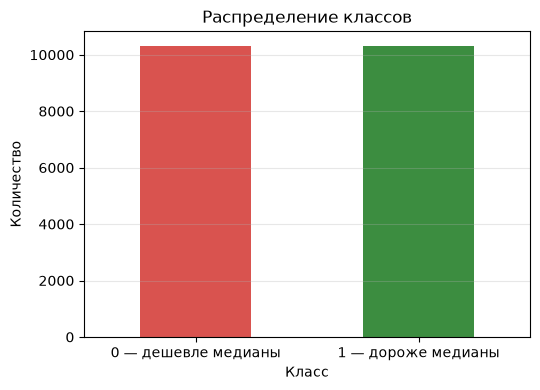

In [10]:
plt.figure(figsize=(5.5, 4))
df[classification_target].value_counts().sort_index().plot(
    kind="bar", color=["#d9534f", "#3c8d40"])
plt.title("Распределение классов")
plt.xlabel("Класс")
plt.ylabel("Количество")
plt.xticks([0, 1], ["0 — дешевле медианы", "1 — дороже медианы"], rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Какую колонку выбрал для классификации.** Готовой колонки-класса в датасете нет,
поэтому создал её сам.

**По какому правилу.** Класс 1 присваивается району, где медианная цена жилья не
ниже медианы по всему датасету, класс 0 — остальным. То есть задача формулируется
как «дорогой район или дешёвый».

**Сколько объектов в каждом классе** — числа выше. Деление по медиане по
определению даёт почти равные группы.

**Сбалансированы ли классы.** Да, примерно поровну. Это удобно: accuracy не будет
вводить в заблуждение, как было бы при соотношении девяносто к десяти.

**Важно про утечку.** Класс создан из `MedHouseVal`, поэтому саму эту колонку в
признаки брать нельзя ни в коем случае — иначе модель получит ответ на вход.
Обе целевые колонки удаляются в следующем задании.

## Задание 6. Подготовка признаков

In [11]:
columns_to_drop = [regression_target, classification_target]

X = df.drop(columns=columns_to_drop)
X = X.drop(columns=["id"], errors="ignore")
X = pd.get_dummies(X, drop_first=True)

print("Признаков:", X.shape[1])
X.head()

Признаков: 8


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [12]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


Удалены обе целевые колонки. ID-колонки в датасете нет. Категориальных признаков
тоже нет — все восемь колонок числовые, поэтому `get_dummies` ничего не изменил.

## Задание 7. Обработка пропусков

In [13]:
print("Пропуски в X:")
print(X.isnull().sum().to_string())

X = X.fillna(X.median(numeric_only=True))

print("\nПосле заполнения:", int(X.isnull().sum().sum()))

Пропуски в X:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0

После заполнения: 0


**Были ли пропуски.** Нет, ни в одной колонке. Заполнение медианой выполнено как
того требует задание, но фактически ничего не изменило.

**Почему нельзя игнорировать пропуски.** Большинство моделей sklearn на `NaN`
просто падают с ошибкой. Там, где не падают, пропуск искажает статистику:
среднее, корреляции и границы разбиения в дереве считаются по неполным данным.
Медиана в качестве замены устойчивее среднего, потому что её не сдвигают выбросы.

## Задание 8. Деление на train и test

In [14]:
X_train, X_test, y_reg_train, y_reg_test, y_cls_train, y_cls_test = train_test_split(
    X, y_reg, y_cls, test_size=0.2, random_state=42, stratify=y_cls)

print("X_train:    ", X_train.shape)
print("X_test:     ", X_test.shape)
print("y_reg_train:", y_reg_train.shape)
print("y_reg_test: ", y_reg_test.shape)
print("y_cls_train:", y_cls_train.shape)
print("y_cls_test: ", y_cls_test.shape)

X_train:     (16512, 8)
X_test:      (4128, 8)
y_reg_train: (16512,)
y_reg_test:  (4128,)
y_cls_train: (16512,)
y_cls_test:  (4128,)


**Сколько данных в train и test** — числа выше: 80 процентов на обучение,
20 на проверку.

**Зачем делить.** Чтобы измерить качество на данных, которых модель не видела.

**Почему нельзя проверять на обучающих данных.** Модель способна их просто
запомнить. Дерево без ограничения глубины доводит точность на train почти до
единицы, но это говорит о памяти, а не об умении обобщать. Такая проверка
показала бы отличный результат у заведомо бесполезной модели.

## Задание 9. Масштабирование признаков

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Среднее по train после масштабирования:", round(float(X_train_scaled.mean()), 6))
print("Стандартное отклонение:                ", round(float(X_train_scaled.std()), 6))
print("Среднее по test:                       ", round(float(X_test_scaled.mean()), 4))

Среднее по train после масштабирования: 0.0
Стандартное отклонение:                 1.0
Среднее по test:                        -0.0093


**Что делает StandardScaler.** Приводит каждый признак к среднему 0 и
стандартному отклонению 1, вычитая среднее и деля на отклонение.

**Почему scaler обучается только на train.** Среднее и отклонение — это знание о
данных. Посчитав их по всей таблице, мы протащим в обучение информацию о тестовой
выборке, и оценка качества окажется завышенной. Это data leakage.

**Для каких моделей масштабирование особенно важно.** Для всех, кто опирается на
расстояния и на величину коэффициентов: KNN, SVM, логистическая и линейная
регрессия с регуляризацией, нейронные сети.

**Почему деревья не требуют масштабирования.** Дерево не измеряет расстояний. Оно
ищет порог вида «признак больше X» и сравнивает значения внутри одной колонки.
Умножение всей колонки на сто не изменит порядок значений, а значит и разбиение.

## Задание 10. Linear Regression

In [16]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_reg_train)
y_reg_pred_lin = lin_reg.predict(X_test_scaled)

pd.DataFrame({
    "real": y_reg_test.values[:10].round(3),
    "predicted": y_reg_pred_lin[:10].round(3),
})

,real,predicted
0,1.232,1.816
1,0.811,1.230
2,2.053,2.454
3,2.796,2.846
4,1.601,2.318
5,1.099,1.538
6,1.070,1.175
7,1.690,2.075
8,2.588,2.658
9,0.681,1.166


In [17]:
mae_lin = mean_absolute_error(y_reg_test, y_reg_pred_lin)
mse_lin = mean_squared_error(y_reg_test, y_reg_pred_lin)
rmse_lin = mse_lin ** 0.5
r2_lin = r2_score(y_reg_test, y_reg_pred_lin)

print("MAE: ", round(mae_lin, 4))
print("MSE: ", round(mse_lin, 4))
print("RMSE:", round(rmse_lin, 4))
print("R2:  ", round(r2_lin, 4))
print(f"\nОшибка в долларах: примерно ${mae_lin * 100_000:,.0f}")

MAE: 

 0.5315
MSE:  0.5074
RMSE: 0.7123
R2:   0.6101

Ошибка в долларах: примерно $53,148


## Задание 11. Decision Tree Regressor

In [18]:
dt_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
dt_reg.fit(X_train, y_reg_train)
y_reg_pred_dt = dt_reg.predict(X_test)

mae_dt = mean_absolute_error(y_reg_test, y_reg_pred_dt)
mse_dt = mean_squared_error(y_reg_test, y_reg_pred_dt)
rmse_dt = mse_dt ** 0.5
r2_dt = r2_score(y_reg_test, y_reg_pred_dt)

print("MAE: ", round(mae_dt, 4))
print("MSE: ", round(mse_dt, 4))
print("RMSE:", round(rmse_dt, 4))
print("R2:  ", round(r2_dt, 4))

MAE:  0.5133
MSE:  0.4921
RMSE: 0.7015
R2:   0.6219


## Задание 12. Random Forest Regressor

In [19]:
rf_reg = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
rf_reg.fit(X_train, y_reg_train)
y_reg_pred_rf = rf_reg.predict(X_test)

mae_rf = mean_absolute_error(y_reg_test, y_reg_pred_rf)
mse_rf = mean_squared_error(y_reg_test, y_reg_pred_rf)
rmse_rf = mse_rf ** 0.5
r2_rf = r2_score(y_reg_test, y_reg_pred_rf)

print("MAE: ", round(mae_rf, 4))
print("MSE: ", round(mse_rf, 4))
print("RMSE:", round(rmse_rf, 4))
print("R2:  ", round(r2_rf, 4))

MAE:  0.3966
MSE:  0.3194
RMSE: 0.5652
R2:   0.7546


## Задание 13. Таблица сравнения регрессионных моделей

In [20]:
regression_results = pd.DataFrame({
    "model": ["Linear Regression", "Decision Tree Regressor", "Random Forest Regressor"],
    "MAE": [mae_lin, mae_dt, mae_rf],
    "MSE": [mse_lin, mse_dt, mse_rf],
    "RMSE": [rmse_lin, rmse_dt, rmse_rf],
    "R2": [r2_lin, r2_dt, r2_rf],
}).round(4)

regression_results

,model,MAE,MSE,RMSE,R2
0,Linear Regression,0.5315,0.5074,0.7123,0.6101
1,Decision Tree Regressor,0.5133,0.4921,0.7015,0.6219
2,Random Forest Regressor,0.3966,0.3194,0.5652,0.7546


In [21]:
regression_results.sort_values("RMSE").reset_index(drop=True)

,model,MAE,MSE,RMSE,R2
0,Random Forest Regressor,0.3966,0.3194,0.5652,0.7546
1,Decision Tree Regressor,0.5133,0.4921,0.7015,0.6219
2,Linear Regression,0.5315,0.5074,0.7123,0.6101


### Вывод по регрессии

Результаты в таблице выше. Лучший результат по всем четырём метрикам сразу
показал Random Forest: у него наименьшие MAE и RMSE и наибольший R².
Одиночное дерево с глубиной 5 оказалось слабее леса, а линейная регрессия —
слабее обоих.

Почему лес сработал лучше. Связь цены с признаками здесь нелинейная: влияние
дохода на стоимость не постоянно, а география вообще задаётся парой координат,
которую прямой не описать. Дерево умеет резать пространство на области и ловить
такие зависимости, а лес усредняет две сотни деревьев и потому не переобучается
так, как одиночное.

Линейная регрессия проигрывает именно из-за формы связи: она способна провести
только одну плоскость через все данные.

Что означает ошибка в контексте датасета. Целевая переменная измеряется в сотнях
тысяч долларов, поэтому MAE нужно умножать на сто тысяч. У леса MAE около 0.40,
то есть промах примерно в 40 тысяч долларов. Средняя цена по датасету 2.07, то
есть около 207 тысяч, значит ошибка составляет порядка 19 процентов от средней
стоимости. Для табличных данных без информации о самом доме это приемлемо, но
назвать точным такое предсказание нельзя: пятая часть цены — серьёзный разброс.
У линейной регрессии ошибка ещё выше, около 53 тысяч.

## Задание 14. Logistic Regression

In [22]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_cls_train)
y_cls_pred_log = log_reg.predict(X_test_scaled)

acc_log = accuracy_score(y_cls_test, y_cls_pred_log)
precision_log = precision_score(y_cls_test, y_cls_pred_log)
recall_log = recall_score(y_cls_test, y_cls_pred_log)
f1_log = f1_score(y_cls_test, y_cls_pred_log)

print("accuracy: ", round(acc_log, 4))
print("precision:", round(precision_log, 4))
print("recall:   ", round(recall_log, 4))
print("f1:       ", round(f1_log, 4))

accuracy:  0.8273
precision: 0.8263
recall:    0.8291
f1:        0.8277


## Задание 15. Decision Tree Classifier

In [23]:
dt_cls = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_cls.fit(X_train, y_cls_train)
y_cls_pred_dt = dt_cls.predict(X_test)

acc_dt = accuracy_score(y_cls_test, y_cls_pred_dt)
precision_dt = precision_score(y_cls_test, y_cls_pred_dt)
recall_dt = recall_score(y_cls_test, y_cls_pred_dt)
f1_dt = f1_score(y_cls_test, y_cls_pred_dt)

print("accuracy: ", round(acc_dt, 4))
print("precision:", round(precision_dt, 4))
print("recall:   ", round(recall_dt, 4))
print("f1:       ", round(f1_dt, 4))

accuracy:  0.796
precision: 0.819
recall:    0.7603
f1:        0.7885


## Задание 16. Random Forest Classifier

In [24]:
rf_cls = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
rf_cls.fit(X_train, y_cls_train)
y_cls_pred_rf = rf_cls.predict(X_test)

acc_rf = accuracy_score(y_cls_test, y_cls_pred_rf)
precision_rf = precision_score(y_cls_test, y_cls_pred_rf)
recall_rf = recall_score(y_cls_test, y_cls_pred_rf)
f1_rf = f1_score(y_cls_test, y_cls_pred_rf)

print("accuracy: ", round(acc_rf, 4))
print("precision:", round(precision_rf, 4))
print("recall:   ", round(recall_rf, 4))
print("f1:       ", round(f1_rf, 4))

accuracy:  0.8728
precision: 0.8808
recall:    0.8625
f1:        0.8715


## Задание 17. Confusion matrix и classification report

In [25]:
predictions = {
    "Logistic Regression": y_cls_pred_log,
    "Decision Tree Classifier": y_cls_pred_dt,
    "Random Forest Classifier": y_cls_pred_rf,
}

for name, pred in predictions.items():
    print("=" * 56)
    print(name)
    print("=" * 56)
    print(pd.DataFrame(confusion_matrix(y_cls_test, pred),
                       index=["реально 0", "реально 1"],
                       columns=["предсказано 0", "предсказано 1"]).to_string())
    print()
    print(classification_report(y_cls_test, pred,
                                target_names=["дешёвый", "дорогой"], digits=3))

Logistic Regression
           предсказано 0  предсказано 1
реально 0           1703            360
реально 1            353           1712

              precision    recall  f1-score   support

     дешёвый      0.828     0.825     0.827      2063
     дорогой      0.826     0.829     0.828      2065

    accuracy                          0.827      4128
   macro avg      0.827     0.827     0.827      4128
weighted avg      0.827     0.827     0.827      4128

Decision Tree Classifier
           предсказано 0  предсказано 1
реально 0           1716            347
реально 1            495           1570

              precision    recall  f1-score   support

     дешёвый      0.776     0.832     0.803      2063
     дорогой      0.819     0.760     0.789      2065

    accuracy                          0.796      4128
   macro avg      0.798     0.796     0.796      4128
weighted avg      0.798     0.796     0.796      4128

Random Forest Classifier
           предсказано 0  предсказ

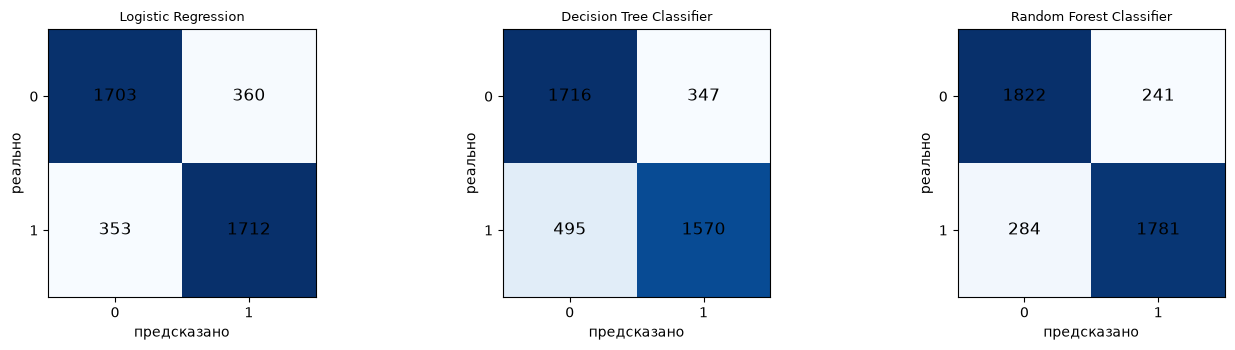

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_cls_test, pred)
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12)
    ax.set_title(name, fontsize=9)
    ax.set_xticks([0, 1], ["0", "1"])
    ax.set_yticks([0, 1], ["0", "1"])
    ax.set_xlabel("предсказано")
    ax.set_ylabel("реально")

plt.tight_layout()
plt.show()

## Задание 18. Таблица сравнения классификаторов

In [27]:
classification_results = pd.DataFrame({
    "model": ["Logistic Regression", "Decision Tree Classifier", "Random Forest Classifier"],
    "accuracy": [acc_log, acc_dt, acc_rf],
    "precision": [precision_log, precision_dt, precision_rf],
    "recall": [recall_log, recall_dt, recall_rf],
    "f1": [f1_log, f1_dt, f1_rf],
}).round(4)

classification_results

,model,accuracy,precision,recall,f1
0,Logistic Regression,0.8273,0.8263,0.8291,0.8277
1,Decision Tree Classifier,0.7960,0.8190,0.7603,0.7885
2,Random Forest Classifier,0.8728,0.8808,0.8625,0.8715


In [28]:
classification_results.sort_values("f1", ascending=False).reset_index(drop=True)

,model,accuracy,precision,recall,f1
0,Random Forest Classifier,0.8728,0.8808,0.8625,0.8715
1,Logistic Regression,0.8273,0.8263,0.8291,0.8277
2,Decision Tree Classifier,0.7960,0.8190,0.7603,0.7885


## Важность признаков

In [29]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_cls.feature_importances_,
}).sort_values("importance", ascending=False)

feature_importance.head(10)

,feature,importance
0,MedInc,0.399019
6,Latitude,0.167733
7,Longitude,0.146192
5,AveOccup,0.130522
2,AveRooms,0.080880
1,HouseAge,0.033664
3,AveBedrms,0.027922
4,Population,0.014067


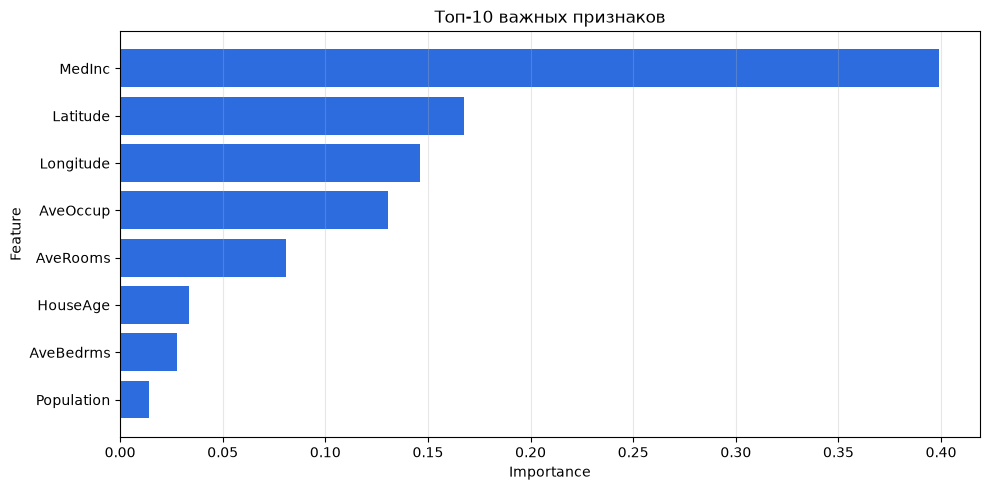

In [30]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 5))
plt.barh(top_features["feature"], top_features["importance"], color="#2d6cdf")
plt.gca().invert_yaxis()
plt.title("Топ-10 важных признаков")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Какие признаки оказались самыми важными** — видно на графике. С большим отрывом
лидирует доход жителей района, за ним идут географические координаты.

**Совпадает ли это с логикой.** Да. Доход напрямую определяет, какое жильё люди
могут себе позволить, а координаты в Калифорнии кодируют близость к побережью и
к Сан-Франциско с Лос-Анджелесом.

**Есть ли неожиданные признаки.** Удивляет низкая важность числа комнат: казалось
бы, размер жилья должен решать. Но в датасете это среднее по району, а не площадь
конкретного дома, поэтому признак слабо различает районы.

**Можно ли полностью доверять feature importance.** Нет. Эта метрика показывает,
как часто и насколько удачно признак использовался при разбиениях, а не причинную
связь. При коррелирующих признаках важность размазывается между ними случайным
образом: широта и долгота по отдельности почти бессмысленны, работает только их
сочетание.

## Задание 19. Влияние max_depth

In [31]:
rows = []
for depth in [2, 3, 4, 5, 8, 10, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_cls_train)
    pred = model.predict(X_test)

    rows.append({
        "max_depth": str(depth),
        "train_accuracy": round(model.score(X_train, y_cls_train), 4),
        "test_accuracy": round(accuracy_score(y_cls_test, pred), 4),
        "f1": round(f1_score(y_cls_test, pred), 4),
        "реальная_глубина": model.get_depth(),
    })

depth_table = pd.DataFrame(rows)
depth_table

,max_depth,train_accuracy,test_accuracy,f1,реальная_глубина
0,2,0.7396,0.7372,0.6968,2
1,3,0.7750,0.7733,0.7626,3
2,4,0.7909,0.7859,0.7649,4
3,5,0.7992,0.7960,0.7885,5
4,8,0.8792,0.8486,0.8502,8
5,10,0.9120,0.8568,0.8575,10
6,None,1.0000,0.8391,0.8398,21


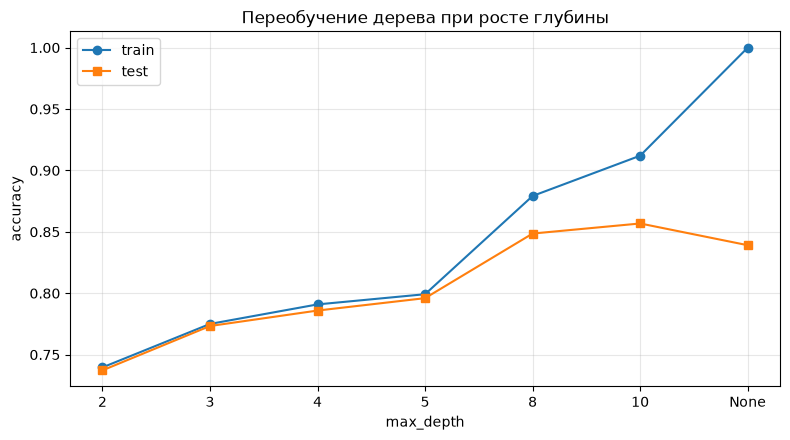

In [32]:
plt.figure(figsize=(8, 4.5))
x = range(len(depth_table))
plt.plot(x, depth_table["train_accuracy"], marker="o", label="train")
plt.plot(x, depth_table["test_accuracy"], marker="s", label="test")
plt.xticks(x, depth_table["max_depth"])
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.title("Переобучение дерева при росте глубины")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**При какой глубине результат лучший** — видно в таблице по колонке `f1`.

**Что произошло при max_depth=None.** Дерево выросло до своей естественной
глубины и запомнило обучающую выборку: точность на train подскочила почти к
единице, а на тесте упала. Разрыв между двумя линиями на графике и есть
переобучение в чистом виде.

**Почему глубокое дерево переобучается.** Каждое новое разбиение дробит выборку
на всё более мелкие группы. В какой-то момент в листе остаётся несколько
объектов, и дерево начинает описывать не закономерность, а конкретные примеры со
всем их шумом. На новых данных такие правила не работают.

## Задание 20. Влияние n_estimators

In [33]:
rows = []
for n in [10, 50, 100, 200, 500]:
    model = RandomForestClassifier(n_estimators=n, max_depth=8, random_state=42, n_jobs=-1)
    model.fit(X_train, y_cls_train)
    pred = model.predict(X_test)

    rows.append({
        "n_estimators": n,
        "accuracy": round(accuracy_score(y_cls_test, pred), 4),
        "f1": round(f1_score(y_cls_test, pred), 4),
    })

estimators_table = pd.DataFrame(rows)
estimators_table

,n_estimators,accuracy,f1
0,10,0.8636,0.8622
1,50,0.8723,0.8711
2,100,0.8726,0.8713
3,200,0.8728,0.8715
4,500,0.8743,0.8726


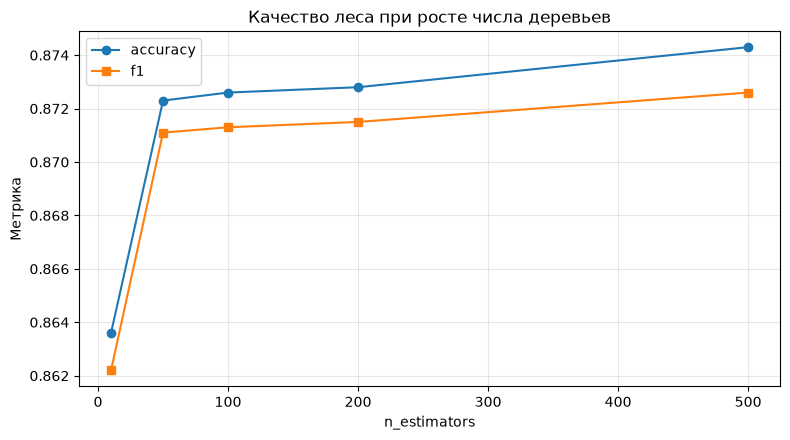

In [34]:
plt.figure(figsize=(8, 4.5))
plt.plot(estimators_table["n_estimators"], estimators_table["accuracy"], marker="o", label="accuracy")
plt.plot(estimators_table["n_estimators"], estimators_table["f1"], marker="s", label="f1")
plt.xlabel("n_estimators")
plt.ylabel("Метрика")
plt.title("Качество леса при росте числа деревьев")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**При каком числе деревьев результат лучший** — видно в таблице, и разница между
значениями крайне мала.

**Всегда ли больше деревьев значит лучше.** Нет. Качество растёт быстро на первых
десятках деревьев, а дальше выходит на плато. Переход с 200 на 500 практически
ничего не даёт.

**Что меняется при увеличении n_estimators.** Усредняется больше независимых
мнений, поэтому предсказание становится устойчивее и меньше зависит от случайности
конкретной подвыборки. Переобучения при этом не возникает — в отличие от роста
глубины, добавление деревьев само по себе модель не портит.

**Как это влияет на скорость.** Линейно: пятьсот деревьев обучаются примерно в
пять раз дольше сотни. При выходе качества на плато это чистая трата времени.

## Итоговые таблицы

### Таблица 1. Regression results

In [35]:
regression_results.sort_values("RMSE").reset_index(drop=True)

,model,MAE,MSE,RMSE,R2
0,Random Forest Regressor,0.3966,0.3194,0.5652,0.7546
1,Decision Tree Regressor,0.5133,0.4921,0.7015,0.6219
2,Linear Regression,0.5315,0.5074,0.7123,0.6101


### Таблица 2. Classification results

In [36]:
classification_results.sort_values("f1", ascending=False).reset_index(drop=True)

,model,accuracy,precision,recall,f1
0,Random Forest Classifier,0.8728,0.8808,0.8625,0.8715
1,Logistic Regression,0.8273,0.8263,0.8291,0.8277
2,Decision Tree Classifier,0.7960,0.8190,0.7603,0.7885


## Финальный вывод

В работе использован датасет California Housing — данные переписи населения
Калифорнии 1990 года, 20 640 районов и восемь числовых признаков. Он подходит
под требования задания: строк многократно больше ста пятидесяти, признаков
больше пяти, есть числовая колонка для регрессии.

Задача регрессии состояла в предсказании `MedHouseVal` — медианной стоимости
жилья в районе. Задача классификации была создана самостоятельно: район относится
к классу 1, если цена не ниже медианы по датасету, и к классу 0 иначе. Классы
получились сбалансированными, примерно поровну.

С регрессией лучше всех справился Random Forest Regressor: у него минимальные
MAE и RMSE и максимальный R². Одиночное дерево отстало, а линейная регрессия
показала худший результат из трёх. Причина в нелинейности связи: цена зависит от
дохода и географии непрямолинейно, и прямая такую зависимость описать не может.

С классификацией лидер тот же — Random Forest Classifier с F1 около 0.87. А вот
аутсайдер поменялся: второе место заняла логистическая регрессия с 0.83, и хуже
всех выступило одиночное дерево с 0.79. Это любопытный разворот по сравнению с
регрессией, где дерево обгоняло линейную модель.

Объяснение в форме задачи. Граница между дорогими и дешёвыми районами проходит
по доходу почти монотонно, и прямая описывает её неплохо. Одиночное же дерево с
глубиной 5 вынуждено резать пространство прямоугольниками и на плавной границе
теряет точность. Лесу эти ограничения не мешают: усреднение многих деревьев
сглаживает ступенчатость.

Разрыв между лучшей и худшей моделью в классификации меньше, чем в регрессии:
восемь сотых по F1 против полутора десятых по R².

Для регрессии использованы MAE, MSE, RMSE и R². MAE удобен тем, что измеряется в
тех же единицах, что и цена, и его можно переводить в доллары. RMSE сильнее
штрафует крупные промахи. R² показывает долю объяснённого разброса.

Для классификации использованы accuracy, precision, recall, F1 и confusion matrix.
Здесь классы сбалансированы, поэтому accuracy не обманывает, но F1 всё равно
информативнее: он учитывает, какой ценой достигнута точность.

Масштабирование нужно моделям, которые работают с расстояниями и величиной
коэффициентов: логистической и линейной регрессии, KNN, SVM, нейронным сетям.
Без него признак с большим размахом подавляет остальные. Деревьям и лесу
масштабирование не нужно — они сравнивают значения внутри одной колонки, и
монотонное преобразование порядок не меняет. В работе scaler обучался строго на
train и применялся к test через `transform`.

Самым важным признаком оказался медианный доход жителей района, за ним следуют
географические координаты. Число комнат и возраст застройки влияют слабее, чем
можно было ожидать, потому что в датасете это усреднённые по району величины.

Утечка данных могла возникнуть в двух местах, и оба закрыты. Первое: колонка
класса создана из `MedHouseVal`, поэтому использовать её как признак было бы
прямой подсказкой ответа — обе целевые колонки удалены из X. Второе:
масштабирование по всей таблице протащило бы в обучение статистику тестовой
выборки — scaler обучен только на train.

Что улучшил бы в следующей версии. Добавил бы кросс-валидацию вместо одного
разбиения, подбор гиперпараметров через GridSearchCV и градиентный бустинг для
сравнения. Отдельно стоило бы разобраться с «потолком» цены: в исходных данных
стоимость обрезана сверху значением 5.0, и такие районы образуют искусственный
пик, который модель пытается выучить как настоящую закономерность.

## Контрольные вопросы

**Чем регрессия отличается от классификации.** Регрессия предсказывает
непрерывное число, классификация — принадлежность к одной из категорий.

**Почему Linear Regression не подходит для предсказания классов.** Она выдаёт
любое число, в том числе отрицательное или больше единицы, и его нельзя
истолковать как вероятность. К тому же она минимизирует квадрат отклонения, а не
ошибку отнесения к классу.

**Почему Logistic Regression называется regression, но используется для
классификации.** Внутри она строит обычную линейную комбинацию признаков, то есть
регрессию, но результат пропускает через сигмоиду, которая сжимает его в
промежуток от нуля до единицы. Это уже вероятность класса.

**Что показывает MAE.** Среднюю абсолютную ошибку в единицах целевой переменной.

**Что показывает RMSE.** Корень из среднего квадрата ошибки. Та же размерность,
что у цели, но крупные промахи наказываются сильнее.

**Что показывает R².** Долю разброса целевой переменной, объяснённую моделью.
Единица — идеальное попадание, ноль — не лучше предсказания средним.

**Что показывает accuracy.** Долю правильных ответов среди всех.

**Что показывает precision.** Среди объектов, названных положительными, какая
доля действительно положительна. Отвечает на вопрос «как часто модель зря бьёт
тревогу».

**Что показывает recall.** Среди настоящих положительных, какую долю модель нашла.
Отвечает на вопрос «сколько мы пропустили».

**Что показывает F1-score.** Гармоническое среднее precision и recall. Высок
только тогда, когда обе величины высоки.

**Что такое confusion matrix.** Таблица, где по строкам настоящие классы, а по
столбцам предсказанные. Видно не только сколько ошибок, но и какого они рода.

**Что такое train/test split.** Разделение данных на часть для обучения и часть
для честной проверки.

**Что такое масштабирование.** Приведение признаков к сопоставимому диапазону,
чтобы величина единиц измерения не влияла на модель.

**Почему нельзя обучать scaler на test.** Среднее и отклонение тестовой выборки —
это информация о ней. Попав в обучение, она завысит оценку качества, и на
настоящих новых данных результат окажется хуже.

**Что такое Decision Tree.** Модель из последовательности вопросов вида «признак
больше порога», где каждый ответ ведёт в следующую ветку, а лист даёт итог.

**Что такое Random Forest.** Ансамбль из многих деревьев, обученных на случайных
подвыборках объектов и признаков. Итог определяется голосованием или усреднением.

**Почему Random Forest стабильнее одного дерева.** Ошибки отдельных деревьев
независимы и при усреднении гасят друг друга, поэтому лес слабее реагирует на
случайные особенности обучающей выборки.

**Что такое переобучение.** Состояние, когда модель запомнила обучающие примеры
вместе с шумом вместо того, чтобы выучить закономерность. Узнаётся по разрыву
между качеством на train и test.

**Как max_depth влияет на дерево.** Ограничивает число последовательных вопросов.
Малое значение ведёт к недообучению, слишком большое — к переобучению.

**Как n_estimators влияет на Random Forest.** Задаёт число деревьев. Рост сначала
улучшает устойчивость, затем выходит на плато, а время обучения растёт линейно.